In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

In [2]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)

In [ ]:
kolumny = [
    "tx_id", "found_at", "has_rbf",
    "rbf_fee_total", "absolute_fee",
    "absolute_fee_original",
    "fee_rate", "fee_rate_original",
    "waittime", "mempool_tx_count"
]

data = data_raw.select(kolumny).to_pandas()


data

## Przygotowanie danych

In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Korzystamy z istniejącej tabeli data_raw
kolumny = [
    "tx_id", "found_at", "has_rbf",
    "rbf_fee_total", "absolute_fee",
    "absolute_fee_original",
    "fee_rate", "fee_rate_original",
    "waittime", "mempool_tx_count"
]

dostepne = [
    k for k in kolumny
    if k in data_raw.schema.names
]

df = data_raw.select(dostepne).to_pandas()

df["has_rbf"] = pd.to_numeric(
    df["has_rbf"], errors="coerce"
)
df["found_at"] = pd.to_datetime(
    df["found_at"], errors="coerce"
)

# Tylko jednoznacznie oznaczone obserwacje
df = df[df["has_rbf"].isin([0, 1])].copy()

liczba_rbf = (df["has_rbf"] == 1).sum()
udzial_rbf = 100 * liczba_rbf / len(df)

print("Liczba transakcji RBF:", liczba_rbf)
print(f"Udział RBF: {udzial_rbf:.2f}%")


Liczba transakcji RBF: 125788
Udział RBF: 1.13%


## Zmiany opłat godzina po godzinie

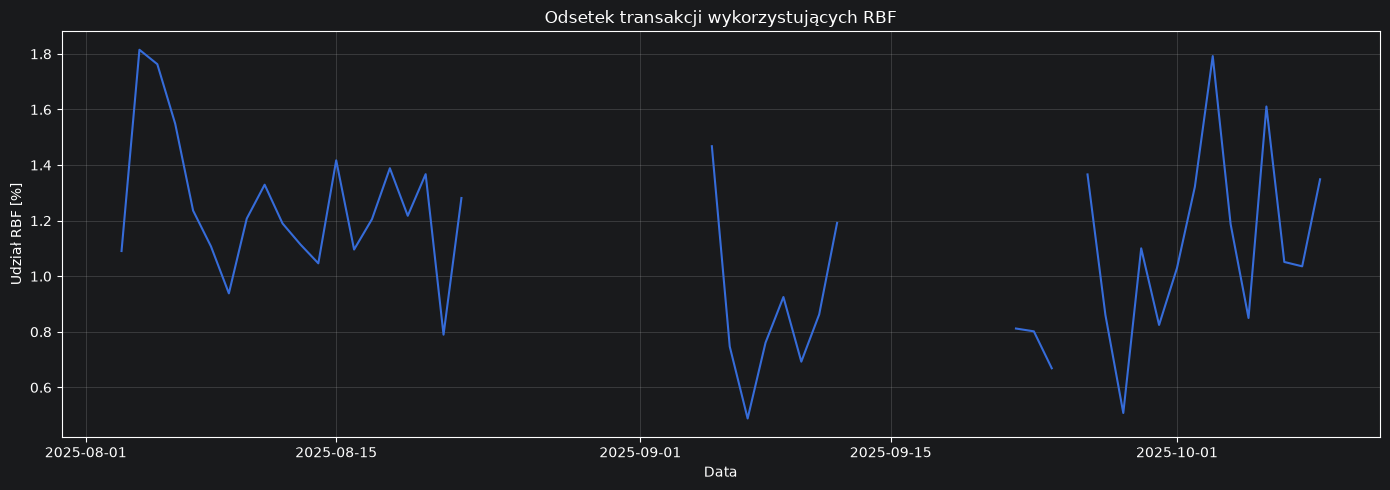

In [18]:
dzienne = (
    df.dropna(subset=["found_at"])
    .groupby(df["found_at"].dt.floor("D"))["has_rbf"]
    .agg(["size", "sum"])
)

dzienne["udzial_rbf"] = (
    100 * dzienne["sum"] / dzienne["size"]
)

# Brakujące dni pozostają NaN
dzienne = dzienne.asfreq("D")

plt.figure(figsize=(14, 5))

plt.plot(
    dzienne.index,
    dzienne["udzial_rbf"]
)

plt.xlabel("Data")
plt.ylabel("Udział RBF [%]")
plt.title("Odsetek transakcji wykorzystujących RBF")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
rbf = df[df["has_rbf"] == 1].copy()

kolumny_oplat = [
    "rbf_fee_total",
    "absolute_fee",
    "absolute_fee_original",
    "fee_rate",
    "fee_rate_original"
]

display(
    rbf[kolumny_oplat].describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    ).T
)

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
rbf_fee_total,125788.0,2075.429683,15222.783091,77.0,308.000000,508.000000,876.000000,1692.000000,4060.000000,6728.000000,18142.380000,4.326140e+06
absolute_fee,125788.0,2069.312581,15222.127746,41.0,306.000000,504.000000,876.000000,1687.000000,4057.000000,6688.650000,18126.390000,4.326140e+06
absolute_fee_original,125788.0,607.121554,2915.696562,10.0,75.000000,141.000000,290.000000,636.000000,1240.000000,1728.000000,4260.000000,5.210290e+05
fee_rate,125788.0,13.147388,130.068921,0.0,2.010929,3.020979,5.035461,8.530144,22.566964,48.868349,137.614679,3.968936e+04
fee_rate_original,125788.0,3.364733,18.365448,0.0,0.000000,1.000000,2.000000,4.000000,7.000000,10.000000,25.000000,3.954000e+03


## Analiza danych z rfb i bez

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

kolumny = [
    "has_rbf",
    "found_at",
    "fee_rate",
    "absolute_fee",
    "waittime",
    "mempool_tx_count",
    "is_cpfp_package"
]

# Wczytanie danych z kolumną RBF
if "has_rbf" in data_raw.schema.names:
    dostepne = [
        c for c in kolumny
        if c in data_raw.schema.names
    ]
    df = data_raw.select(dostepne).to_pandas()

elif "has_rbf" in data.columns:
    dostepne = [
        c for c in kolumny if c in data.columns
    ]
    df = data[dostepne].copy()

else:
    raise ValueError(
        "Brak kolumny has_rbf w data i data_raw. "
        "Nie można wiarygodnie rozdzielić grup."
    )

df["has_rbf"] = pd.to_numeric(
    df["has_rbf"], errors="coerce"
)

df = df[df["has_rbf"].isin([0, 1])].copy()

df["found_at"] = pd.to_datetime(
    df["found_at"], errors="coerce"
)

for c in ["fee_rate", "absolute_fee",
          "waittime", "mempool_tx_count"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")
        df.loc[df[c] < 0, c] = np.nan

df["grupa"] = np.where(
    df["has_rbf"] == 1,
    "RBF",
    "Bez RBF"
)

# Dwie osobne grupy
rbf = df[df["has_rbf"] == 1].copy()
bez_rbf = df[df["has_rbf"] == 0].copy()

print("Transakcje RBF:", len(rbf))
print("Transakcje bez RBF:", len(bez_rbf))
print("Udział RBF:", round(100 * len(rbf)/len(df), 2), "%")


Transakcje RBF: 125788
Transakcje bez RBF: 10984489
Udział RBF: 1.13 %


In [21]:
zmienne = {
    "fee_rate": "Stawka opłaty [sat/vB]",
    "absolute_fee": "Opłata całkowita [sat]",
    "waittime": "Czas potwierdzenia [s]",
    "mempool_tx_count": "Liczba transakcji w mempoolu"
}

for kolumna, opis in zmienne.items():

    if kolumna not in df.columns:
        continue

    stat = df.groupby("grupa")[kolumna].agg(
        n="count",
        srednia="mean",
        mediana="median",
        std="std",
        p10=lambda x: x.quantile(0.10),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99)
    )

    stat["CV"] = stat["std"] / stat["srednia"]

    print("\n", opis)
    display(stat.round(3))



 Stawka opłaty [sat/vB]


,n,srednia,mediana,std,p10,p90,p95,p99,CV
grupa,,,,,,,,,
Bez RBF,10984489,4.146,2.973,11.476,1.007,7.136,10.033,30.214,2.768
RBF,125788,13.147,5.035,130.069,2.011,22.567,48.868,137.615,9.893



 Opłata całkowita [sat]


,n,srednia,mediana,std,p10,p90,p95,p99,CV
grupa,,,,,,,,,
Bez RBF,10984489,1194.016,452.0,14887.156,154.0,1830.0,2910.00,11292.00,12.468
RBF,125788,2069.313,876.0,15222.128,306.0,4057.0,6688.65,18126.39,7.356



 Czas potwierdzenia [s]


,n,srednia,mediana,std,p10,p90,p95,p99,CV
grupa,,,,,,,,,
Bez RBF,10984489,1352.691,477.0,8125.135,91.0,2194.0,4023.0,15759.00,6.007
RBF,125788,8365.297,1362.0,57858.021,311.0,7710.3,14995.0,140823.08,6.916



 Liczba transakcji w mempoolu


,n,srednia,mediana,std,p10,p90,p95,p99,CV
grupa,,,,,,,,,
Bez RBF,10984489,37834.169,10441.792,38697.272,1510.764,92479.993,99674.750,109456.333,1.023
RBF,125788,41313.481,37856.424,37882.231,2204.569,91579.910,98787.979,109456.333,0.917


#### Boxploty opłat i czasów potwierdzenia

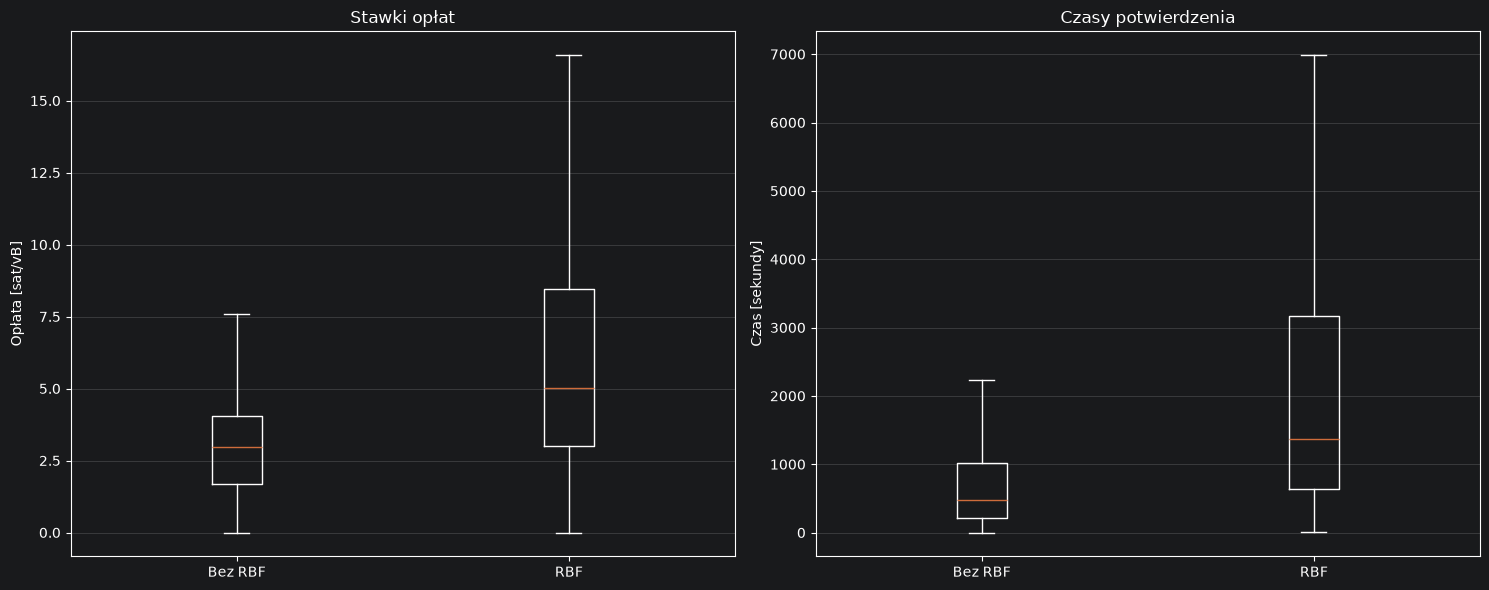

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, kolumna, tytul in zip(
    axes,
    ["fee_rate", "waittime"],
    ["Stawki opłat", "Czasy potwierdzenia"]
):

    probki = []

    for grupa in [bez_rbf, rbf]:
        s = grupa[kolumna].dropna()
        probki.append(
            s.sample(
                n=min(30_000, len(s)),
                random_state=42
            ).to_numpy()
        )

    ax.boxplot(
        probki,
        showfliers=False
    )

    ax.set_xticks([1, 2], ["Bez RBF", "RBF"])
    ax.set_title(tytul)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Opłata [sat/vB]")
axes[1].set_ylabel("Czas [sekundy]")

plt.tight_layout()
plt.show()


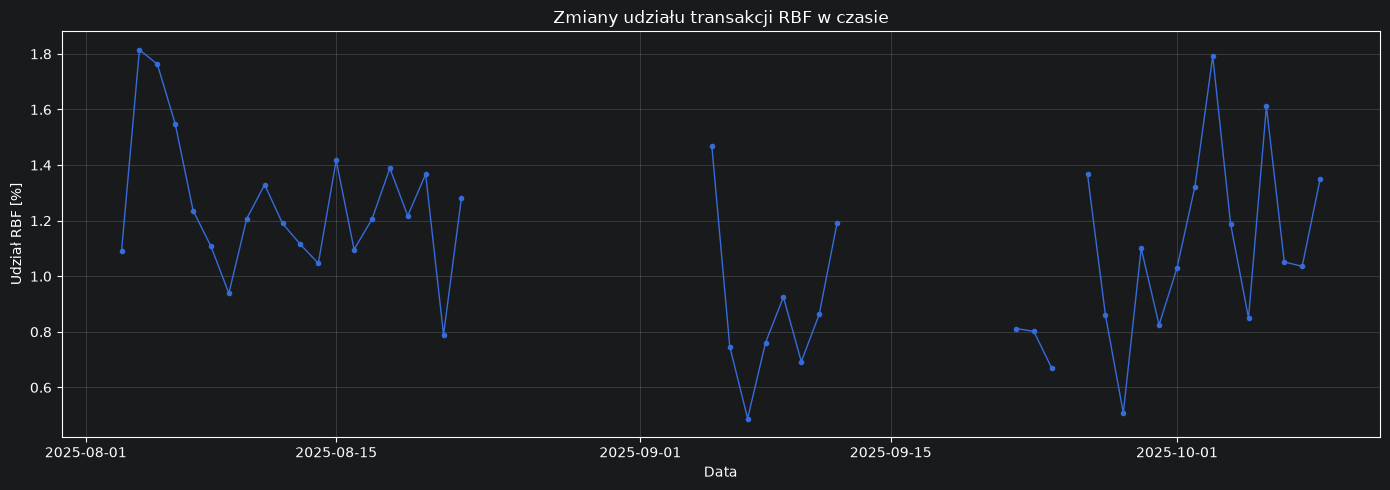

In [23]:

dzienne = (
    df.dropna(subset=["found_at"])
    .assign(dzien=lambda x: x["found_at"].dt.floor("D"))
    .groupby("dzien")["has_rbf"]
    .agg(["count", "sum"])
)

dzienne["udzial_rbf"] = (
    100 * dzienne["sum"] / dzienne["count"]
)

dzienne = dzienne.asfreq("D")

plt.figure(figsize=(14, 5))

plt.plot(
    dzienne.index,
    dzienne["udzial_rbf"],
    marker=".",
    linewidth=1
)

plt.xlabel("Data")
plt.ylabel("Udział RBF [%]")
plt.title("Zmiany udziału transakcji RBF w czasie")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:
prog1 = pd.Timestamp("2025-09-01 20:44:17")
prog2 = pd.Timestamp("2025-09-15 20:44:17")
prog3 = pd.Timestamp("2025-09-26 02:44:17")

df["okres"] = pd.cut(
    df["found_at"],
    bins=[
        pd.Timestamp("1900-01-01"),
        prog1, prog2, prog3,
        pd.Timestamp("2100-01-01")
    ],
    labels=["Okres 1", "Okres 2", "Okres 3", "Okres 4"],
    right=False
)

porownanie = (
    df.groupby(["okres", "grupa"], observed=True)
    .agg(
        liczba=("has_rbf", "size"),
        mediana_oplaty=("fee_rate", "median"),
        mediana_czasu=("waittime", "median"),
        srednia_oplata=("fee_rate", "mean")
    )
)

display(porownanie.round(3))

udzial_okresy = (
    df.groupby("okres", observed=True)["has_rbf"]
    .mean() * 100
)

print("Udział RBF w okresach [%]:")
print(udzial_okresy.round(2))

liczba  mediana_oplaty  mediana_czasu  srednia_oplata
okres   grupa                                                          
Okres 1 Bez RBF  5480547           3.014          493.0           4.245
        RBF        69772           5.031         1597.0          13.174
Okres 2 Bez RBF  1754364           2.236          426.0           3.911
        RBF        14860           4.312         1043.0          13.205
Okres 3 Bez RBF   446318           2.027          417.0           3.480
        RBF         3473           4.013          909.0           9.323
Okres 4 Bez RBF  3303260           2.979          485.0           4.196
        RBF        37683           5.293         1298.0          13.428

Udział RBF w okresach [%]:
okres
Okres 1    1.26
Okres 2    0.84
Okres 3    0.77
Okres 4    1.13
Name: has_rbf, dtype: float64


### Czy udział RBF wzrasta wraz z zatłoczeniem mempoola?

In [25]:

# Pobranie wymaganych danych
kolumny = ["has_rbf", "mempool_tx_count", "found_at"]

if all(c in data_raw.schema.names for c in kolumny):
    df_h3 = data_raw.select(kolumny).to_pandas()
elif all(c in data.columns for c in kolumny):
    df_h3 = data[kolumny].copy()
else:
    raise ValueError(
        "Brakuje wymaganych kolumn: "
        "has_rbf, mempool_tx_count lub found_at"
    )

for c in ["has_rbf", "mempool_tx_count"]:
    df_h3[c] = pd.to_numeric(df_h3[c], errors="coerce")

df_h3["found_at"] = pd.to_datetime(
    df_h3["found_at"], errors="coerce"
)

df_h3 = df_h3.replace([np.inf, -np.inf], np.nan)
df_h3 = df_h3.dropna(subset=kolumny)

df_h3 = df_h3[
    df_h3["has_rbf"].isin([0, 1]) &
    (df_h3["mempool_tx_count"] >= 0)
].copy()

# Podział zatłoczenia mempoola na decyle
df_h3["decyl"] = pd.qcut(
    df_h3["mempool_tx_count"],
    q=10,
    duplicates="drop"
)

stat = df_h3.groupby("decyl", observed=True).agg(
    liczba_tx=("has_rbf", "size"),
    liczba_rbf=("has_rbf", "sum"),
    mediana_mempool=("mempool_tx_count", "median")
)

stat["udzial_rbf"] = (
    100 * stat["liczba_rbf"] / stat["liczba_tx"]
)

print(stat.round(3))


                         liczba_tx  liczba_rbf  mediana_mempool  udzial_rbf
decyl                                                                      
(631.268, 1510.764]        1112383        4709         1225.201       0.423
(1510.764, 2084.542]       1116480        6431         1765.403       0.576
(2084.542, 2915.514]       1111791       10283         2471.132       0.925
(2915.514, 4550.451]       1113804       14320         3547.889       1.286
(4550.451, 10496.417]      1109763       19001         6548.660       1.712
(10496.417, 55607.514]     1107507       15809        42685.674       1.427
(55607.514, 69179.861]     1108930       14444        63955.708       1.303
(69179.861, 82039.049]     1110437       13812        78352.076       1.244
(82039.049, 92479.993]     1113314       14889        86954.153       1.337
(92479.993, 119623.986]    1105868       12090        99674.750       1.093


### Wykres: udział RBF a zatłoczenie mempoola

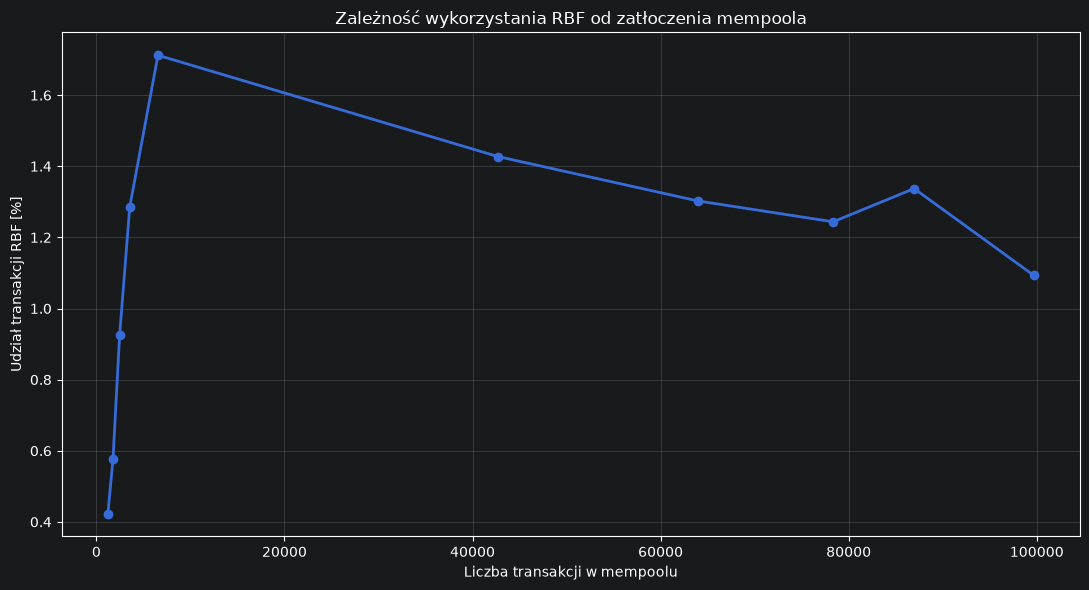

In [26]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    stat["mediana_mempool"],
    stat["udzial_rbf"],
    marker="o",
    linewidth=2
)

ax.set_xlabel("Liczba transakcji w mempoolu")
ax.set_ylabel("Udział transakcji RBF [%]")
ax.set_title("Zależność wykorzystania RBF od zatłoczenia mempoola")

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Zmiany opłat

In [31]:
kolumny = data_raw.schema.names

# Szukamy wszystkich potencjalnie przydatnych pól
szukane = [
    "rbf", "replace", "fee", "time",
    "found", "seen", "conflict", "input"
]

wynik = [
    k for k in kolumny
    if any(s in k.lower() for s in szukane)
]

print("\n".join(wynik))

found_at
fee_rate_original
waittime
rbf_fee_total
absolute_fee_original
fee_rate
absolute_fee
block_time
block_median_feerate
block_p10_feerate
block_p90_feerate
time_since_last_block
ema_feerate_3block
found_at_ts
fee_rate_percentile
log_waittime
log_fee_rate
log_block_median_feerate
log_block_p90_feerate
log_ema_feerate_3block
log_time_since_last_block
has_rbf


In [32]:
dostepne = [
    k for k in [
        "tx_id",
        "found_at",
        "mined_at",
        "has_rbf",
        "rbf_fee_total",
        "fee_rate",
        "fee_rate_original"
    ]
    if k in kolumny
]

podglad = data_raw.select(dostepne).to_pandas()

if "has_rbf" in podglad.columns:
    display(podglad[podglad["has_rbf"] == 1].head(20))
else:
    display(podglad.head(20))

,tx_id,found_at,mined_at,has_rbf,rbf_fee_total,fee_rate,fee_rate_original
647,098091231a66b4c75c2e441e75d5dd8b6c3016e9411d8e...,2025-09-11 18:39:30,2025-09-11 20:57:13,1,987.0,7.050000,1.0
1143,ad1830c5295c8b89b9c1249b8b06273dd8159f4e8673c9...,2025-09-11 20:31:40,2025-09-11 20:57:13,1,295.0,2.418033,1.0
1319,96c33d93a42475810366672b27b76bd4d8f25ba37b5ffa...,2025-09-11 20:48:22,2025-09-11 20:57:13,1,1696.0,8.037915,1.0
1467,848d9241ffccc7d3fa80fba66ee3b8665b9de68bcd25d7...,2025-09-11 20:55:14,2025-09-11 20:57:13,1,1064.0,4.045627,3.0
1781,e4f7da6cb95d1bc5a8227487d106ea937ee0ce9cd28d33...,2025-09-23 01:19:42,2025-09-23 01:33:40,1,532.0,2.022814,1.0
1976,485e8d02fa8069e5316bebe0d635ae9172abeb2e29e2cd...,2025-09-23 01:20:38,2025-09-23 01:33:38,1,400.0,3.571429,2.0
2111,e3025ca95bc24ede656ff0e2d6d1039ea849cb8af1a81c...,2025-09-23 01:21:20,2025-09-23 01:33:38,1,705.0,5.035714,2.0
2311,7d9ea16453541c09b82ddccf2772a969540038ba20b84f...,2025-09-23 01:22:40,2025-09-23 01:33:39,1,510.0,2.512315,2.0
2506,d278c057e64f68d88dfa9bfddfc84bccd5fbd45344470d...,2025-09-23 01:24:09,2025-09-23 01:33:38,1,2260.0,16.028369,1.0
4171,ae7e46a4b96c2aba0b40d12a6342241fd3cf00d8e55ec7...,2025-10-02 13:49:16,2025-10-02 14:35:39,1,423.0,3.021429,1.0
